In [1]:
import pyvista as pv
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------------
# Read the final VTK files
# ------------------------------------------------------------------

base = Path("varyDt")

dt01 = pv.read(base / "dt_0.01" / "output_3000.vti")
dt02 = pv.read(base / "dt_0.02" / "output_1500.vti")
dt03 = pv.read(base / "dt_0.03" / "output_0990.vti")
dt04 = pv.read(base / "dt_0.04" / "output_0750.vti")
dt05 = pv.read(base / "dt_0.05" / "output_0600.vti")

In [2]:
# Extract C1 and C2

dt01_C1 = dt01["C1"].reshape((40, 40))
dt01_C2 = dt01["C2"].reshape((40, 40))

dt02_C1 = dt02["C1"].reshape((40, 40))
dt02_C2 = dt02["C2"].reshape((40, 40))

dt03_C1 = dt03["C1"].reshape((40, 40))
dt03_C2 = dt03["C2"].reshape((40, 40))

dt04_C1 = dt04["C1"].reshape((40, 40))
dt04_C2 = dt04["C2"].reshape((40, 40))

dt05_C1 = dt05["C1"].reshape((40, 40))
dt05_C2 = dt05["C2"].reshape((40, 40))

In [3]:
vmin1 = min(
    dt01_C1.min(),
    dt02_C1.min(),
    dt03_C1.min(),
    dt04_C1.min(),
    dt05_C1.min()
)

vmax1 = max(
    dt01_C1.max(),
    dt02_C1.max(),
    dt03_C1.max(),
    dt04_C1.max(),
    dt05_C1.max()
)

vmin2 = min(
    dt01_C2.min(),
    dt02_C2.min(),
    dt03_C2.min(),
    dt04_C2.min(),
    dt05_C1.min()
)

vmax2 = max(
    dt01_C2.max(),
    dt02_C2.max(),
    dt03_C2.max(),
    dt04_C2.max(),
    dt05_C1.max()
)

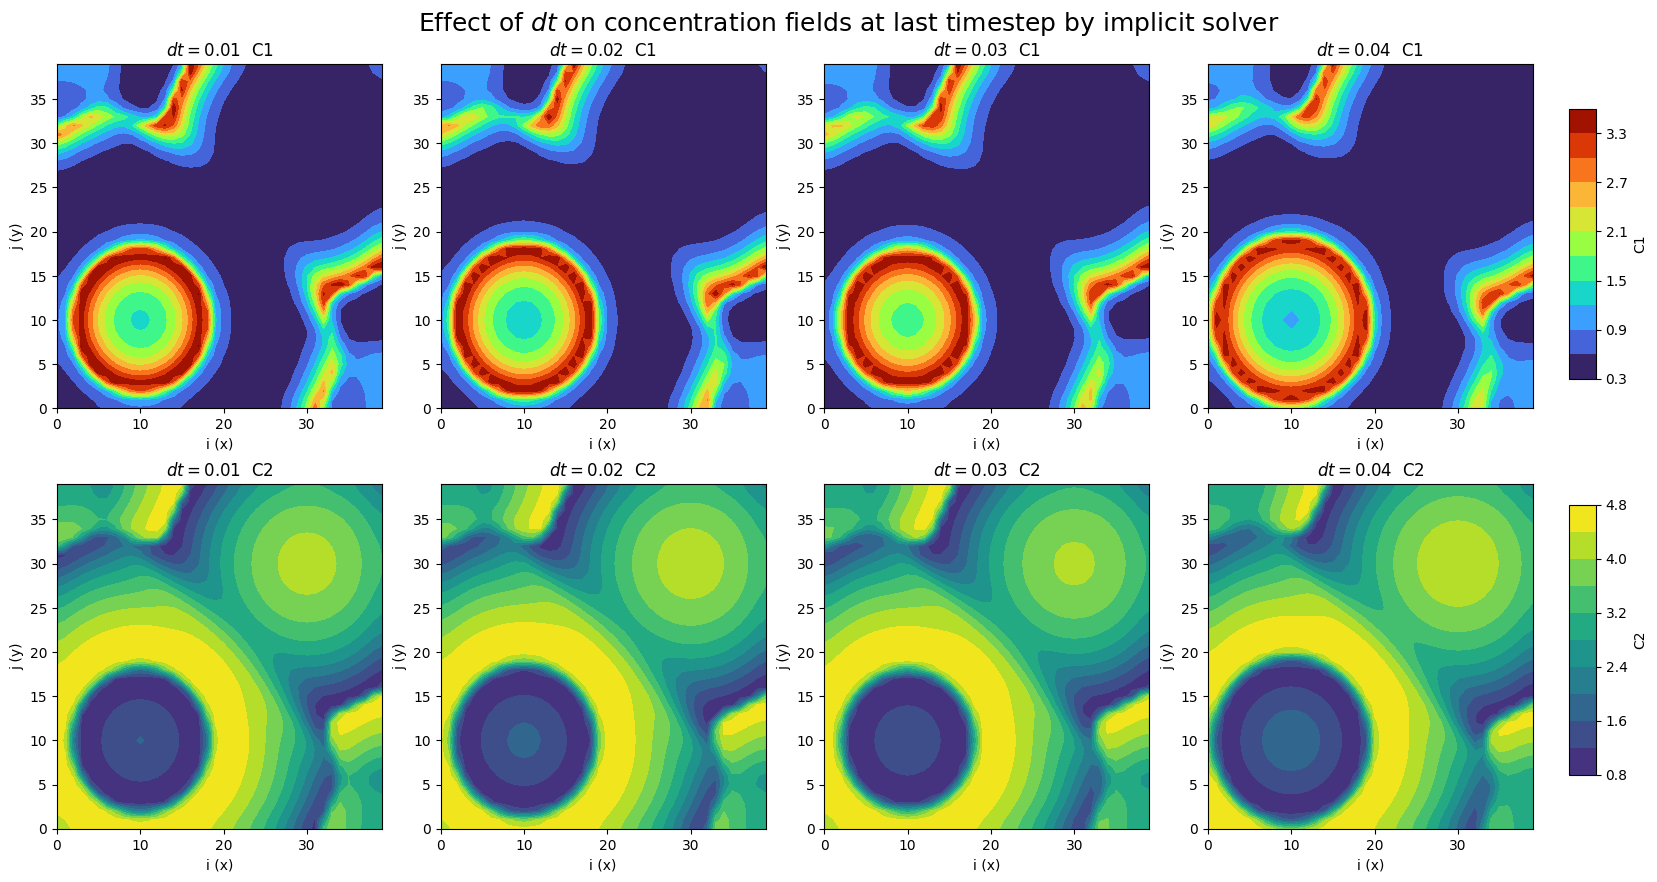

In [4]:
# Create figure
fig, axs = plt.subplots(2, 4, figsize=(18, 9))

fig.suptitle(
    r"Effect of $dt$ on concentration fields at last timestep by implicit solver",
    fontsize=18
)

titles = [
    r"$dt=0.01$",
    r"$dt=0.02$",
    r"$dt=0.03$",
    r"$dt=0.04$"
]

C1_list = [
    dt01_C1,
    dt02_C1,
    dt03_C1,
    dt04_C1,
    dt05_C1
]

C2_list = [
    dt01_C2,
    dt02_C2,
    dt03_C2,
    dt04_C2,
    dt05_C2
]

for i in range(4):

    im1 = axs[0, i].contourf(
        C1_list[i],
        levels=10,
        cmap="turbo",
        vmin=vmin1,
        vmax=vmax1
    )

    axs[0, i].set_title(titles[i] + "  C1")
    axs[0, i].set_xlabel("i (x)")
    axs[0, i].set_ylabel("j (y)")

    im2 = axs[1, i].contourf(
        C2_list[i],
        levels=10,
        cmap="viridis",
        vmin=vmin2,
        vmax=vmax2
    )

    axs[1, i].set_title(titles[i] + "  C2")
    axs[1, i].set_xlabel("i (x)")
    axs[1, i].set_ylabel("j (y)")


# Leave some room on the right
plt.subplots_adjust(right=0.88)
# Create separate axes for the colorbars
cax1 = fig.add_axes([0.90, 0.57, 0.015, 0.30])  # [left, bottom, width, height]
cax2 = fig.add_axes([0.90, 0.13, 0.015, 0.30])

#Draw the colorbars
cbar1 = fig.colorbar(im1,cax=cax1)
cbar1.set_label("C1")

cbar2 = fig.colorbar(im2,cax=cax2)
cbar2.set_label("C2")

plt.subplots_adjust(
    left=0.06,
    right=0.88,
    bottom=0.07,
    top=0.92,
    wspace=0.18,
    hspace=0.22
)

#Save the figure
plt.savefig("Effect of dt variation on concentration fields using implicit solver.png", dpi=300,bbox_inches="tight")

plt.show()